# Praktikum 1 - HDBSCAN vs DBSCAN: Robustness dan Scale Invariance

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 05:** Klasterisasi Hierarki

### Tujuan Praktikum:
1. Memahami perbedaan mendasar antara DBSCAN dan **HDBSCAN (Hierarchical Density-Based Spatial Clustering of Applications with Noise)**.
2. Mengamati sensitivitas parameter jarak `eps` pada DBSCAN terhadap perubahan skala data (*scale invariance issue*).
3. Membangun model HDBSCAN yang mampu beradaptasi otomatis terhadap variasi densitas cluster dan skala tanpa memerlukan penentuan parameter `eps` secara manual.

## Langkah 1 - Import Modul dan Library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import DBSCAN
try:
    from sklearn.cluster import HDBSCAN
except ImportError:
    import hdbscan
    HDBSCAN = hdbscan.HDBSCAN

## Langkah 2 - Definisi Fungsi Visualisasi
Fungsi `plot` untuk memvisualisasikan data klaster di mana ukuran marker berbanding lurus dengan nilai probabilitas keanggotaan klaster (`probabilities_`), dan noise ditandai dengan warna hitam.

In [2]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}
    
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                'x' if k == -1 else 'o',
                markerfacecolor=tuple(col),
                markeredgecolor='k',
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = 'True' if ground_truth else 'Estimated'
    title = f'{preamble} number of clusters: {n_clusters_}'
    if parameters is not None:
        parameters_str = ', '.join(f'{k}={v}' for k, v in parameters.items())
        title += f' | {parameters_str}'
    ax.set_title(title)
    plt.tight_layout()

## Langkah 3 - Membuat Dataset Sintetis dengan Ragam Densitas

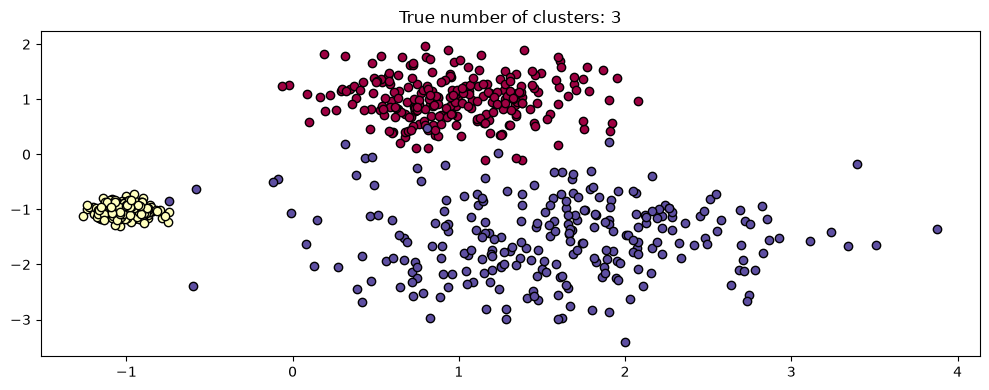

In [3]:
centers = [[1, 1], [-1, -1], [1.5, -1.5]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.4, 0.1, 0.75], random_state=0
)

plot(X, labels=labels_true, ground_truth=True)
plt.show()

## Langkah 4 - Uji Sensitivitas Skala (Scale Invariance) pada DBSCAN
Menerapkan DBSCAN dengan nilai `eps=0.3` statis pada data yang diskalakan (faktor pengali 1, 0.5, dan 3). Terlihat bahwa DBSCAN gagal mempertahankan struktur klaster ketika skala data berubah.

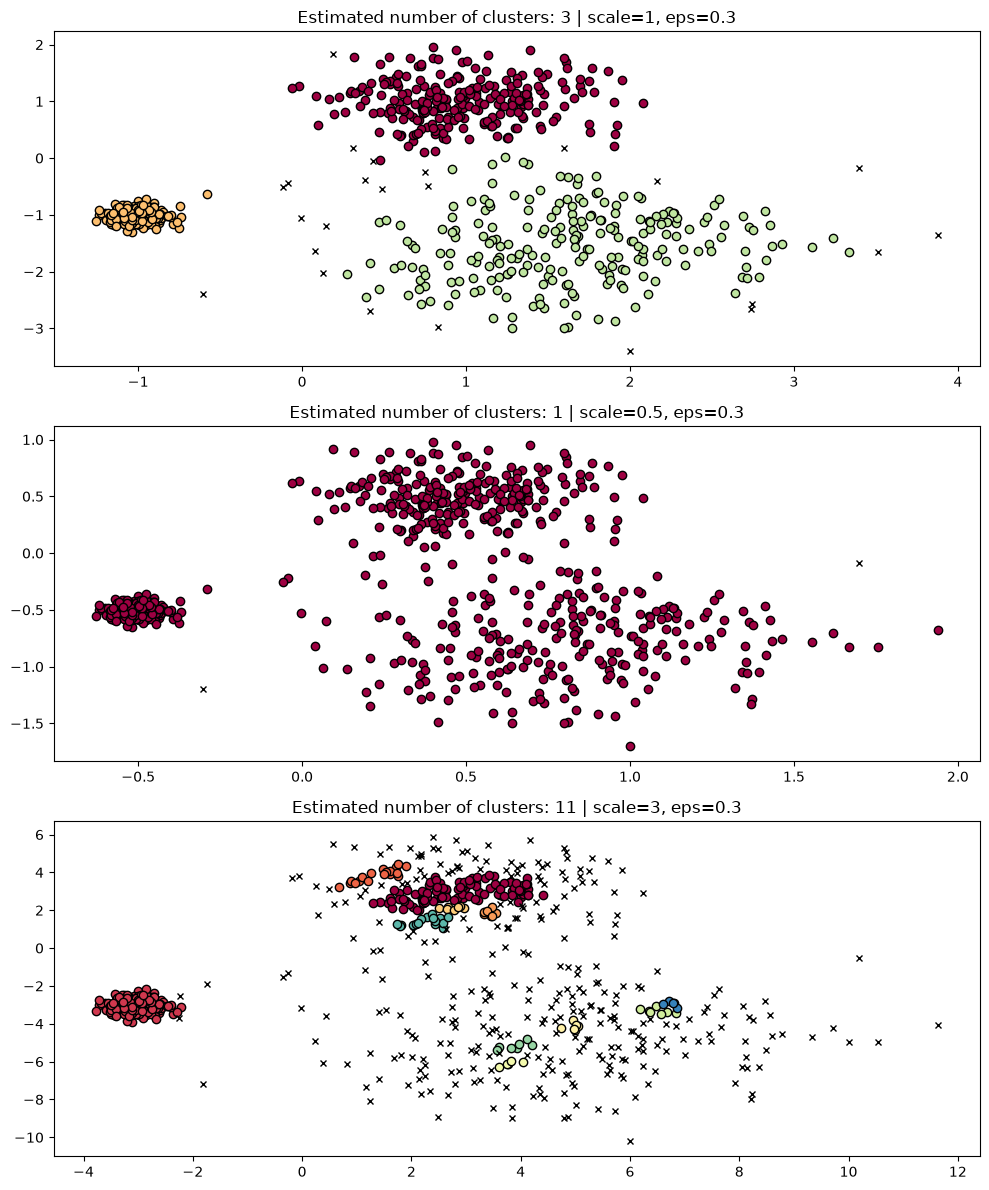

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=0.3)
for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X * scale)
    plot(X * scale, dbs.labels_, parameters={'scale': scale, 'eps': 0.3}, ax=axes[idx])
plt.show()

## Langkah 5 - Penerapan HDBSCAN
HDBSCAN mengonstruksi pohon hierarki kepadatan (*spanning tree*) sehingga dapat mendeteksi klaster secara mandiri tanpa memerlukan penentuan nilai `eps` secara kaku.

C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


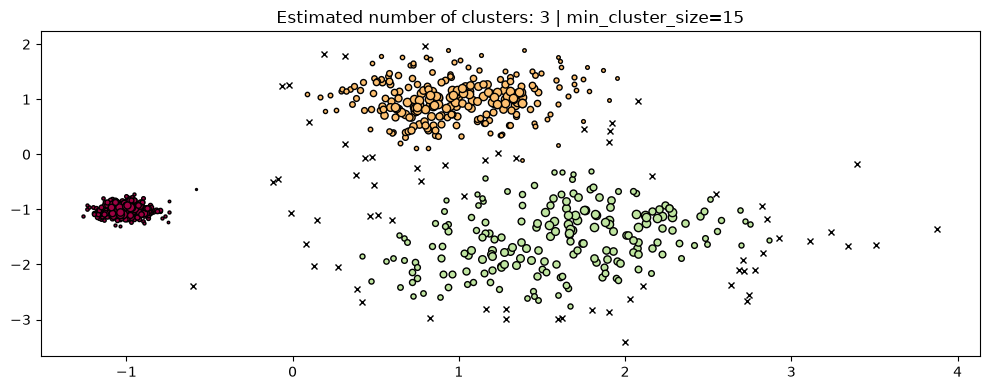

Jumlah klaster terdeteksi oleh HDBSCAN: 3
Jumlah data noise: 66


In [5]:
hdb = HDBSCAN(min_cluster_size=15).fit(X)
fig, ax = plt.subplots(figsize=(10, 4))
plot(X, hdb.labels_, probabilities=hdb.probabilities_, parameters={'min_cluster_size': 15}, ax=ax)
plt.show()

n_clusters_hdb = len(set(hdb.labels_)) - (1 if -1 in hdb.labels_ else 0)
n_noise_hdb = list(hdb.labels_).count(-1)
print(f'Jumlah klaster terdeteksi oleh HDBSCAN: {n_clusters_hdb}')
print(f'Jumlah data noise: {n_noise_hdb}')